# BAB 6.1 — MODEL DESIGN: BASELINE MODEL (LOGISTIC REGRESSION + TF-IDF)

**Mata Kuliah:** Data Science (Semester 5)  
**Proyek:** Analisis Klasifikasi Ujaran Kebencian pada Informasi Pemerintahan Indonesia di Media Sosial Menggunakan Machine Learning dan Deep Learning  
**Keterkaitan SDG:** **SDG 16** (*Peace, Justice and Strong Institutions*) — Target 16.10 & 16.7  
**PIC / Anggota 1:** Ardhana Syah Hidayat (244311037)  
**Kolaborator / Anggota 2:** Muhammad Adam Al-Kidri (244311050)  

---

### Tujuan Notebook:
1. **Justifikasi Teoretis Model 1 (Bab 6.1.1):** Menjelaskan teori dasar Logistic Regression dan alasan pemilihannya berdasarkan karakteristik matriks TF-IDF bahasa Indonesia berdimensi tinggi.
2. **Perumusan Matematis (Bab 6.1.2):** Mendefinisikan ruang hipotesis (*Hypothesis Space* $\mathcal{H}$) dan menguraikan tiga asumsi induktif (*Inductive Bias*) utama model.
3. **Ekstraksi Fitur Bebas Leakage:** Melakukan representasi leksikal unigram–bigram TF-IDF (5.000 fitur) dengan fitting **hanya pada Training Set**.
4. **Pelatihan & Evaluasi Validasi (Bab 6.1.3–6.1.4):** Melatih model dengan regularisasi $L_2$ awal ($C=1.0$) dan bobot kelas seimbang, kemudian mencatat performa secara objektif pada **Validation Set** (`val.csv`).
5. **Interpretasi Koefisien (Bab 6.1.5):** Menganalisis kata-kata dengan koefisien positif dan negatif tertinggi untuk memvalidasi kewajaran linguistik model.

## 6.1.1 Teori Dasar & Alasan Pemilihan Model

### A. Teori Dasar Logistic Regression
Logistic Regression adalah model klasifikasi linear probabilistik. Model memprediksi probabilitas bersyarat kelas positif ($y=1$, *Hate Speech*) terhadap vektor fitur input $\mathbf{x}$ melalui transformasi fungsi logistik (sigmoid):

$$P(Y=1 \mid \mathbf{x}) = \sigma(\mathbf{w}^T \mathbf{x} + b) = \frac{1}{1 + e^{-(\mathbf{w}^T \mathbf{x} + b)}}$$

Parameter bobot $\mathbf{w} \in \mathbb{R}^D$ dan bias $b \in \mathbb{R}$ diestimasi melalui minimalisasi fungsi kerugian *Binary Cross-Entropy (Log-Loss)* dengan regularisasi $L_2$ (Ridge):

$$\mathcal{L}(\mathbf{w}, b) = -\frac{1}{N} \sum_{i=1}^N \left[ y_i \log \hat{y}_i + (1 - y_i) \log(1 - \hat{y}_i) \right] + \frac{1}{2C} \|\mathbf{w}\|_2^2$$

### B. Alasan Pemilihan Berdasarkan Karakteristik Data
1. **Ruang Fitur Sparse Berdimensi Tinggi ($D = 5.000$):**
   Ekstraksi teks dengan unigram dan bigram menghasilkan matriks jarang (*sparse matrix*). Teorema *Cover* menyatakan bahwa data yang dipetakan ke ruang berdimensi tinggi memiliki probabilitas lebih besar untuk terpisah secara linear (*linearly separable*). Logistic Regression sangat efisien dan stabil pada ruang *sparse* berdimensi ribuan.
2. **Karakteristik Optimasi Konveks:**
   Fungsi kerugian Log-Loss bersifat *strictly convex*, menjamin konvergensi deterministik menuju minimum global menggunakan *solver* L-BFGS tanpa risiko terperangkap di minimum lokal.
3. **Keterukuran dan Interpretasi (*Baseline Benchmark*):**
   Sebagai model garis dasar (*baseline*), koefisien bobot $\mathbf{w}$ memberikan transparansi penuh untuk mengaudit kata apa yang memicu deteksi ujaran kebencian sebelum melangkah ke model *ensemble* yang lebih kompleks.

## 6.1.2 Hypothesis Space & Inductive Bias

### A. Hypothesis Space ($\mathcal{H}$)
Ruang hipotesis Logistic Regression adalah himpunan seluruh fungsi pemetaan linear terbobot dari ruang fitur $\mathbb{R}^D$ ke rentang probabilitas $(0, 1)$:

$$\mathcal{H} = \left\{ f_{\mathbf{w}, b}(\mathbf{x}) = \frac{1}{1 + e^{-(\mathbf{w}^T \mathbf{x} + b)}} \;\middle|\; \mathbf{w} \in \mathbb{R}^D, \; b \in \mathbb{R} \right\}$$

Batas keputusan (*decision boundary*) pada ambang $\hat{y} = 0.5$ merupakan sebuah bidang datar hiper linear berdimensi $(D-1)$:

$$\text{Decision Boundary} = \left\{ \mathbf{x} \in \mathbb{R}^D \mid \mathbf{w}^T \mathbf{x} + b = 0 \right\}$$

### B. Inductive Bias (Asumsi Dasar Model)
1. **Linearitas Log-Odds (*Linear Separability*):**
   Model mengasumsikan bahwa logaritma rasio peluang (*log-odds*) dari probabilitas ujaran kebencian berbanding lurus secara linear terhadap kombinasi terbobot fitur kata:
   $$\ln \left( \frac{P(Y=1 \mid \mathbf{x})}{1 - P(Y=1 \mid \mathbf{x})} \right) = \mathbf{w}^T \mathbf{x} + b$$
2. **Aditivitas & Independensi Fitur (*Feature Additivity*):**
   Model mengasumsikan kontribusi setiap kata bersifat aditif tanpa interaksi non-linear tingkat tinggi. Keberadaan satu kata menambah atau mengurangi skor secara konstan, terlepas dari keberadaan kata lain (kecuali yang tercakup dalam token bigram).
3. **Prior Gaussian pada Bobot ($L_2$ Ridge Prior):**
   Penalti $\frac{1}{2C} \|\mathbf{w}\|_2^2$ mencerminkan asumsi apriori Bayesian bahwa koefisien bobot berdistribusi normal di sekitar nol ($w_j \sim \mathcal{N}(0, \tau^2)$). Ini mencegah bobot meledak akibat kata langka (*rare words*).

In [1]:
import os
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

# Konfigurasi visualisasi
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print("Library berhasil dimuat.")

Library berhasil dimuat.


### Pemuatan Data Olahan (Bebas Leakage)
Kita membaca data latih (`train.csv`) dan data validasi (`val.csv`) yang telah dipersiapkan pada Bab 5. Data uji (`test.csv`) tetap **disegel** dan tidak dimuat.

In [2]:
# Path adaptif proyek
current_dir = Path.cwd()
root_dir = current_dir if (current_dir / 'data').exists() else current_dir.parent
data_dir = root_dir / 'data' / 'processed'

train_df = pd.read_csv(data_dir / 'train.csv', keep_default_na=False)
val_df = pd.read_csv(data_dir / 'val.csv', keep_default_na=False)

print(f"Data Train      : {len(train_df):,} baris | Distribusi HS: {train_df['HS'].value_counts().to_dict()}")
print(f"Data Validation : {len(val_df):,} baris | Distribusi HS: {val_df['HS'].value_counts().to_dict()}")

X_train_raw = train_df['text_clean_lexical']
y_train = train_df['HS'].values

X_val_raw = val_df['text_clean_lexical']
y_val = val_df['HS'].values

Data Train      : 9,116 baris | Distribusi HS: {0: 5265, 1: 3851}
Data Validation : 1,953 baris | Distribusi HS: {0: 1128, 1: 825}


### Ekstraksi Fitur TF-IDF (Hanya Fit pada Training Set)
Konfigurasi:
* `ngram_range=(1, 2)`: Menangkap unigram dan bigram (misal: "tidak setuju", "presiden jokowi").
* `max_features=5000`: Membatasi 5.000 token paling informatif untuk menjaga densitas sinyal.
* `min_df=2`: Mengeliminasi kata yang hanya muncul 1 kali (mengurangi noise).
* `sublinear_tf=True`: Menerapkan penskalaan sublinear $1 + \log(\text{tf})$ guna meredam dominasi frekuensi kata ekstrem.

In [3]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=5000,
    min_df=2,
    sublinear_tf=True
)

# WAJIB: fit hanya pada train, transform pada train dan val
X_train_tfidf = tfidf.fit_transform(X_train_raw)
X_val_tfidf = tfidf.transform(X_val_raw)

print(f"Dimensi Matriks Fitur Train : {X_train_tfidf.shape}")
print(f"Dimensi Matriks Fitur Val   : {X_val_tfidf.shape}")
print(f"Tingkat Sparsitas Matriks   : {(1.0 - (X_train_tfidf.nnz / (X_train_tfidf.shape[0] * X_train_tfidf.shape[1]))):.4%}")

Dimensi Matriks Fitur Train : (9116, 5000)
Dimensi Matriks Fitur Val   : (1953, 5000)
Tingkat Sparsitas Matriks   : 99.8099%


## 6.1.3 Pelatihan Model & Pencatatan Hiperparameter Awal

Berikut konfigurasi hiperparameter yang digunakan pada pelatihan garis dasar:
* `penalty='l2'`: Regularisasi Ridge standar.
* `C=1.0`: Nilai inverse regularisasi bawaan.
* `class_weight='balanced'`: Menyesuaikan bobot kelas secara terbalik terhadap frekuensi kelas untuk menangani rasio ketimpangan ringan (1,37 : 1).
* `solver='lbfgs'`: Algoritma optimasi kuasi-Newton efisien untuk data sparse.
* `random_state=42`: Menjamin replikasi deterministik.

In [4]:
baseline_model = LogisticRegression(
    penalty='l2',
    C=1.0,
    class_weight='balanced',
    solver='lbfgs',
    max_iter=1000,
    random_state=42
)

# Latih model pada Training Set
baseline_model.fit(X_train_tfidf, y_train)

# Prediksi kelas dan estimasi probabilitas pada Validation Set
y_val_pred = baseline_model.predict(X_val_tfidf)
y_val_proba = baseline_model.predict_proba(X_val_tfidf)[:, 1]

print("Model Baseline (Logistic Regression) berhasil dilatih.")

Model Baseline (Logistic Regression) berhasil dilatih.


C:\Users\USER\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


## 6.1.4 Hasil Evaluasi pada Validation Set
Evaluasi dilakukan murni menggunakan sampel data validasi (`val.csv`). Metrik utama yang diaudit adalah **Macro F1-Score** dan **Precision Kelas 1 (*Hate Speech*)** untuk memitigasi kesalahan *False Positive* (penyensoran kritik wajar).

In [5]:
macro_f1 = f1_score(y_val, y_val_pred, average='macro')
f1_hs = f1_score(y_val, y_val_pred, pos_label=1)
prec_hs = precision_score(y_val, y_val_pred, pos_label=1)
rec_hs = recall_score(y_val, y_val_pred, pos_label=1)
roc_auc = roc_auc_score(y_val, y_val_proba)
pr_auc = average_precision_score(y_val, y_val_proba)

print("=" * 60)
print("HASIL EVALUASI BASELINE MODEL PADA VALIDATION SET (N = 1.953)")
print("=" * 60)
print(f"Macro F1-Score              : {macro_f1:.4f} ({macro_f1:.2%})")
print(f"Precision Kelas 1 (HS)      : {prec_hs:.4f} ({prec_hs:.2%})")
print(f"Recall Kelas 1 (HS)         : {rec_hs:.4f} ({rec_hs:.2%})")
print(f"F1-Score Kelas 1 (HS)       : {f1_hs:.4f} ({f1_hs:.2%})")
print(f"ROC-AUC                     : {roc_auc:.4f} ({roc_auc:.2%})")
print(f"PR-AUC (Average Precision)  : {pr_auc:.4f} ({pr_auc:.2%})")
print("=" * 60)

print("\nLaporan Klasifikasi Rinci:")
print(classification_report(y_val, y_val_pred, target_names=['Non-Hate Speech (0)', 'Hate Speech (1)'], digits=4))

HASIL EVALUASI BASELINE MODEL PADA VALIDATION SET (N = 1.953)
Macro F1-Score              : 0.8251 (82.51%)
Precision Kelas 1 (HS)      : 0.8000 (80.00%)
Recall Kelas 1 (HS)         : 0.7952 (79.52%)
F1-Score Kelas 1 (HS)       : 0.7976 (79.76%)
ROC-AUC                     : 0.9043 (90.43%)
PR-AUC (Average Precision)  : 0.8736 (87.36%)

Laporan Klasifikasi Rinci:
                     precision    recall  f1-score   support

Non-Hate Speech (0)     0.8508    0.8546    0.8527      1128
    Hate Speech (1)     0.8000    0.7952    0.7976       825

           accuracy                         0.8295      1953
          macro avg     0.8254    0.8249    0.8251      1953
       weighted avg     0.8294    0.8295    0.8294      1953



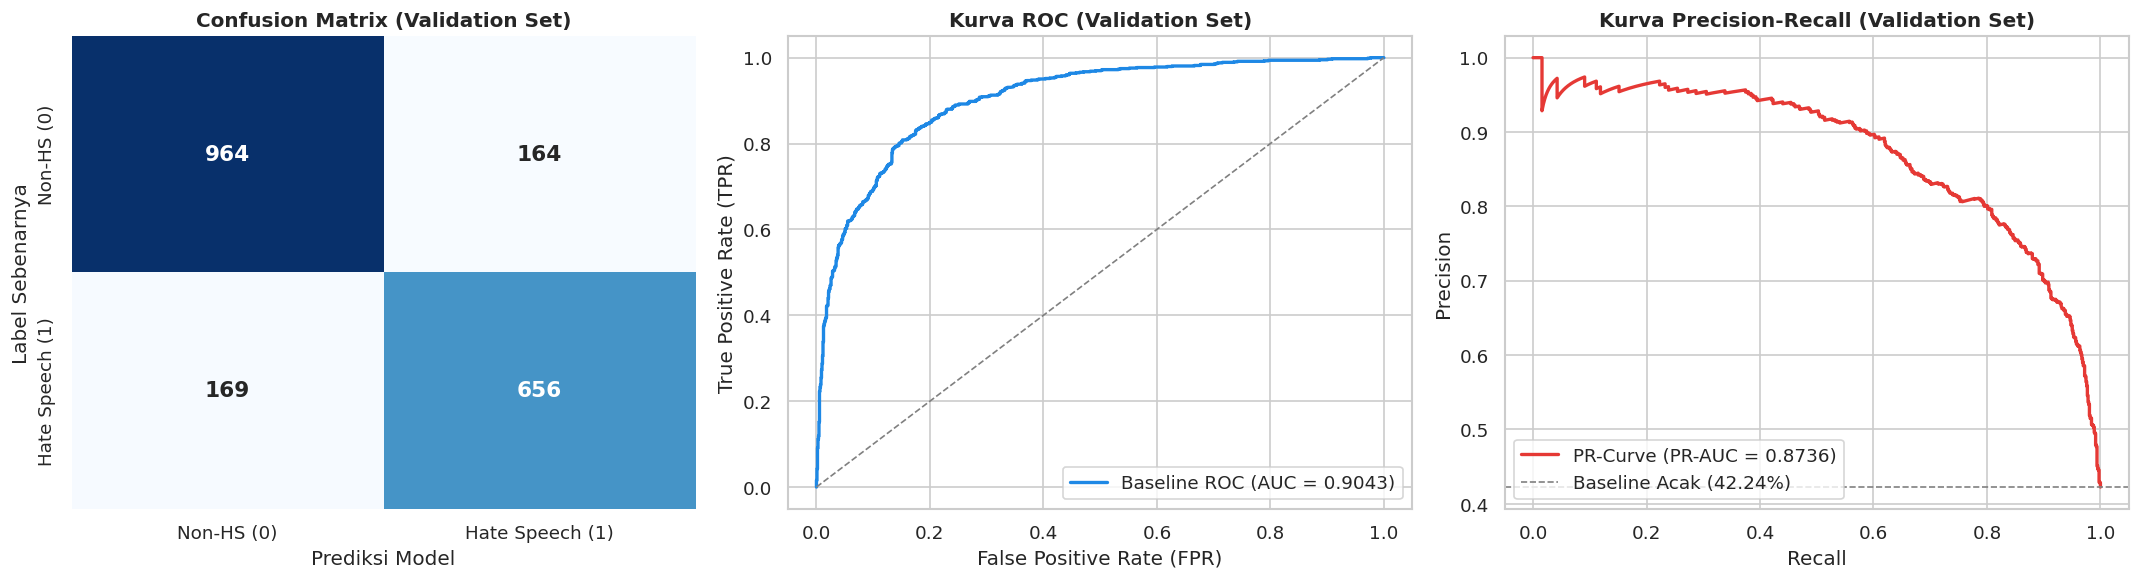

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix Heatmap
cm = confusion_matrix(y_val, y_val_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0],
    xticklabels=['Non-HS (0)', 'Hate Speech (1)'],
    yticklabels=['Non-HS (0)', 'Hate Speech (1)'],
    cbar=False,
    annot_kws={"size": 13, "weight": "bold"}
)
axes[0].set_title('Confusion Matrix (Validation Set)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Prediksi Model')
axes[0].set_ylabel('Label Sebenarnya')

# 2. Kurva ROC
fpr, tpr, _ = roc_curve(y_val, y_val_proba)
axes[1].plot(fpr, tpr, color='#1E88E5', lw=2, label=f'Baseline ROC (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='grey', linestyle='--', lw=1)
axes[1].set_title('Kurva ROC (Validation Set)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('False Positive Rate (FPR)')
axes[1].set_ylabel('True Positive Rate (TPR)')
axes[1].legend(loc='lower right')

# 3. Kurva Precision-Recall
precision_pts, recall_pts, _ = precision_recall_curve(y_val, y_val_proba)
axes[2].plot(recall_pts, precision_pts, color='#E53935', lw=2, label=f'PR-Curve (PR-AUC = {pr_auc:.4f})')
axes[2].axhline(y=y_val.mean(), color='grey', linestyle='--', lw=1, label=f'Baseline Acak ({y_val.mean():.2%})')
axes[2].set_title('Kurva Precision-Recall (Validation Set)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Recall')
axes[2].set_ylabel('Precision')
axes[2].legend(loc='lower left')

plt.tight_layout()
plt.show()

## 6.1.5 Analisis Koefisien Fitur & Interpretasi Linguistik
Keunggulan utama Logistic Regression adalah transparansi matematisnya. Koefisien positif terbesar mengindikasikan fitur leksikal yang paling kuat mendorong prediksi ke arah **Ujaran Kebencian (`HS=1`)**, sedangkan koefisien negatif terbesar menunjukkan penanda kuat **Bukan Ujaran Kebencian (`HS=0`)**.

C:\Users\USER\AppData\Local\Temp\ipykernel_11360\1614789009.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Koefisien', y='Fitur', data=df_top_pos, ax=axes[0], palette='Reds_r')
C:\Users\USER\AppData\Local\Temp\ipykernel_11360\1614789009.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Koefisien', y='Fitur', data=df_top_neg, ax=axes[1], palette='Greens')


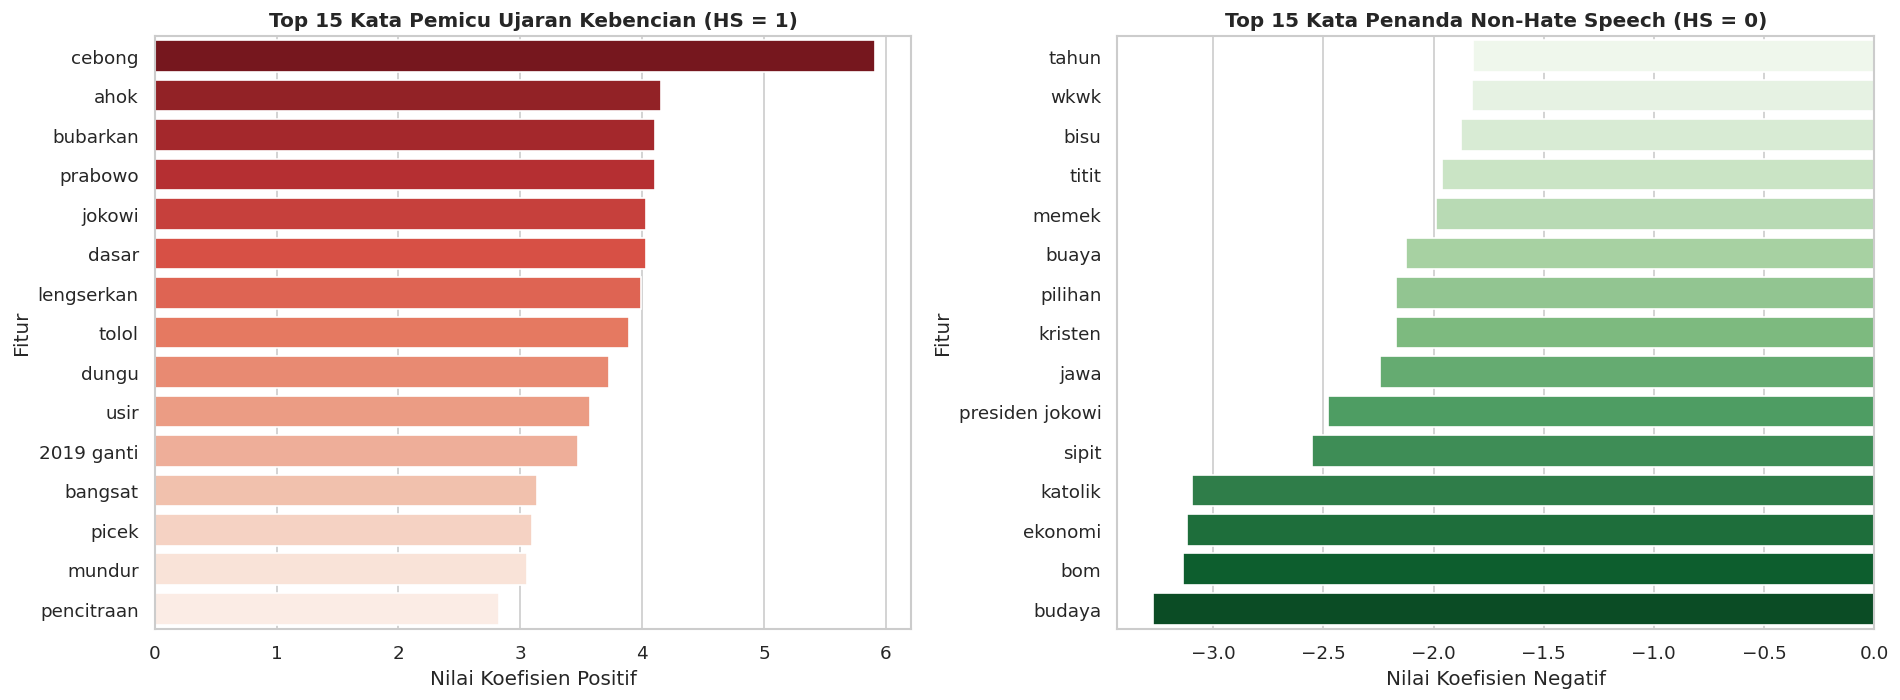

Interpretasi Linguistik Singkat:
1. Kata bernada konfrontatif/ejekan politik (seperti 'cebong', 'bubarkan', 'lengserkan', 'tolol', 'dungu') memiliki bobot positif dominan.
2. Kata bertema netral/kebudayaan (seperti 'budaya', 'ekonomi', 'presiden jokowi') memiliki bobot negatif yang menahan klasifikasi dari vonis ujaran kebencian.


In [7]:
feature_names = np.array(tfidf.get_feature_names_out())
coefs = baseline_model.coef_[0]

top_k = 15
top_pos_idx = np.argsort(coefs)[-top_k:][::-1]
top_neg_idx = np.argsort(coefs)[:top_k]

df_top_pos = pd.DataFrame({
    'Fitur': feature_names[top_pos_idx],
    'Koefisien': coefs[top_pos_idx]
})

df_top_neg = pd.DataFrame({
    'Fitur': feature_names[top_neg_idx],
    'Koefisien': coefs[top_neg_idx]
}).sort_values('Koefisien', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot Koefisien Positif
sns.barplot(x='Koefisien', y='Fitur', data=df_top_pos, ax=axes[0], palette='Reds_r')
axes[0].set_title('Top 15 Kata Pemicu Ujaran Kebencian (HS = 1)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Nilai Koefisien Positif')

# Plot Koefisien Negatif
sns.barplot(x='Koefisien', y='Fitur', data=df_top_neg, ax=axes[1], palette='Greens')
axes[1].set_title('Top 15 Kata Penanda Non-Hate Speech (HS = 0)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Nilai Koefisien Negatif')

plt.tight_layout()
plt.show()

print("Interpretasi Linguistik Singkat:")
print("1. Kata bernada konfrontatif/ejekan politik (seperti 'cebong', 'bubarkan', 'lengserkan', 'tolol', 'dungu') memiliki bobot positif dominan.")
print("2. Kata bertema netral/kebudayaan (seperti 'budaya', 'ekonomi', 'presiden jokowi') memiliki bobot negatif yang menahan klasifikasi dari vonis ujaran kebencian.")

### Eksplorasi Sensitivitas Hiperparameter Regularisasi ($C$)
Untuk memvalidasi bahwa $C=1.0$ adalah pilihan garis dasar yang seimbang, kita melakukan evaluasi sensitivitas pada Validation Set untuk rentang $C \in [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]$.

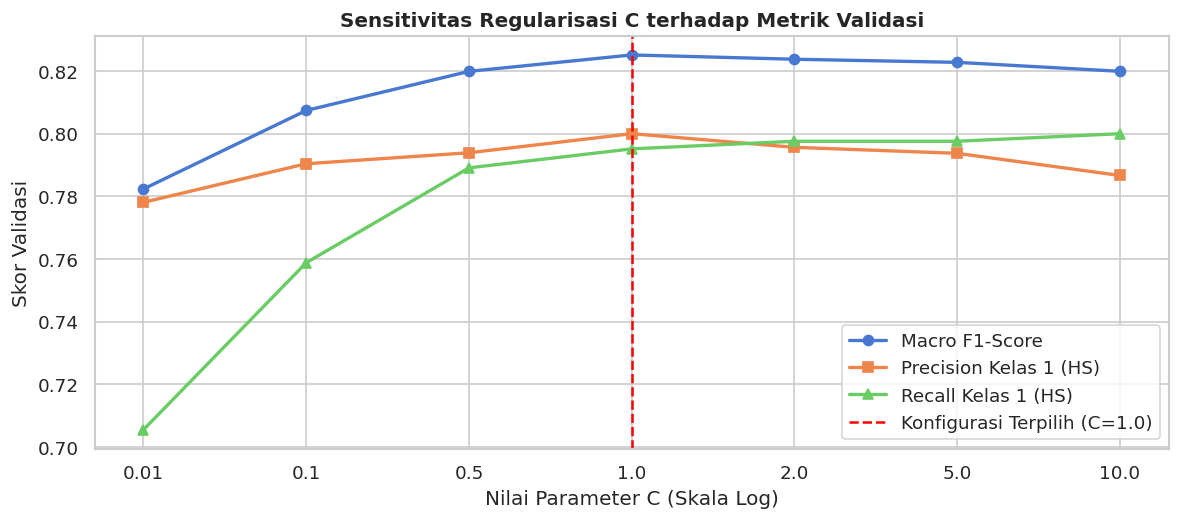

,C,Macro_F1,Precision_HS,Recall_HS,ROC_AUC
0,0.01,0.782338,0.778075,0.705455,0.866364
1,0.10,0.807408,0.790404,0.758788,0.884512
2,0.50,0.819893,0.793902,0.789091,0.899522
3,1.00,0.825144,0.800000,0.795152,0.904290
4,2.00,0.823771,0.795647,0.797576,0.906350
5,5.00,0.822779,0.793727,0.797576,0.904754
6,10.00,0.819917,0.786651,0.800000,0.900770


In [8]:
c_values = [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
c_results = []

for c in c_values:
    clf = LogisticRegression(C=c, class_weight='balanced', max_iter=1000, random_state=42)
    clf.fit(X_train_tfidf, y_train)
    preds = clf.predict(X_val_tfidf)
    probs = clf.predict_proba(X_val_tfidf)[:, 1]
    
    c_results.append({
        'C': c,
        'Macro_F1': f1_score(y_val, preds, average='macro'),
        'Precision_HS': precision_score(y_val, preds, pos_label=1),
        'Recall_HS': recall_score(y_val, preds, pos_label=1),
        'ROC_AUC': roc_auc_score(y_val, probs)
    })

df_c_results = pd.DataFrame(c_results)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(df_c_results['C'].astype(str), df_c_results['Macro_F1'], marker='o', lw=2, label='Macro F1-Score')
ax.plot(df_c_results['C'].astype(str), df_c_results['Precision_HS'], marker='s', lw=2, label='Precision Kelas 1 (HS)')
ax.plot(df_c_results['C'].astype(str), df_c_results['Recall_HS'], marker='^', lw=2, label='Recall Kelas 1 (HS)')
ax.axvline(x=str(1.0), color='red', linestyle='--', label='Konfigurasi Terpilih (C=1.0)')
ax.set_title('Sensitivitas Regularisasi C terhadap Metrik Validasi', fontsize=12, fontweight='bold')
ax.set_xlabel('Nilai Parameter C (Skala Log)')
ax.set_ylabel('Skor Validasi')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

df_c_results

### Penyimpanan Ringkasan Metrik Baseline
Metrik evaluasi pada validation set disimpan ke direktori `results/` untuk digabungkan dengan Model 2 (XGBoost) pada tahap komparasi.

In [9]:
results_dir = root_dir / 'results'
results_dir.mkdir(parents=True, exist_ok=True)

baseline_summary = {
    'model_name': 'Baseline: Logistic Regression',
    'input_features': 'TF-IDF (unigram-bigram, 5000 features)',
    'validation_samples': int(len(val_df)),
    'macro_f1': float(round(macro_f1, 4)),
    'precision_hs': float(round(prec_hs, 4)),
    'recall_hs': float(round(rec_hs, 4)),
    'f1_hs': float(round(f1_hs, 4)),
    'roc_auc': float(round(roc_auc, 4)),
    'pr_auc': float(round(pr_auc, 4)),
    'confusion_matrix': {
        'tn': int(cm[0, 0]),
        'fp': int(cm[0, 1]),
        'fn': int(cm[1, 0]),
        'tp': int(cm[1, 1])
    }
}

metrics_file = results_dir / 'baseline_val_metrics.json'
with open(metrics_file, 'w', encoding='utf-8') as f:
    json.dump(baseline_summary, f, indent=4)

print(f"Ringkasan metrik baseline berhasil disimpan ke: {metrics_file}")

Ringkasan metrik baseline berhasil disimpan ke: D:\TUGAS SEMESTER 5\DATA SCIENCE\id-gov-hatespeech-classification\results\baseline_val_metrics.json
